# Lab 5

Import bibliotek

In [11]:
import sys
import numpy as np
import pandas as pd
import matplotlib as mp
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()
import sklearn

Weryfikacja pakietow

In [12]:
print('Python:       ' + sys.version.split()[0])
print('NumPy:        ' + np.__version__)
print('pandas:       ' + pd.__version__)
print('Matplotlib:   ' + mp.__version__)
print('Seaborn:      ' + sns.__version__)
print('Scikit-learn: ' + sklearn.__version__)

Python:       3.14.0
NumPy:        2.2.6
pandas:       2.3.3
Matplotlib:   3.11.2
Seaborn:      0.13.2
Scikit-learn: 1.7.2


# Przewidywanie postępów cukrzycy


In [13]:
from sklearn.datasets import load_diabetes
X, y = load_diabetes(return_X_y=True, as_frame=True, scaled=False)
X.info()
y.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
dtypes: float64(10)
memory usage: 34.7 KB
<class 'pandas.core.series.Series'>
RangeIndex: 442 entries, 0 to 441
Series name: target
Non-Null Count  Dtype  
--------------  -----  
442 non-null    float64
dtypes: float64(1)
memory usage: 3.6 KB


In [14]:
X.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000
mean,48.518100,1.468326,26.375792,94.647014,189.140271,115.439140,49.788462,4.070249,4.641411,91.260181
std,13.109028,0.499561,4.418122,13.831283,34.608052,30.413081,12.934202,1.290450,0.522391,11.496335
min,19.000000,1.000000,18.000000,62.000000,97.000000,41.600000,22.000000,2.000000,3.258100,58.000000
25%,38.250000,1.000000,23.200000,84.000000,164.250000,96.050000,40.250000,3.000000,4.276700,83.250000
50%,50.000000,1.000000,25.700000,93.000000,186.000000,113.000000,48.000000,4.000000,4.620050,91.000000
75%,59.000000,2.000000,29.275000,105.000000,209.750000,134.500000,57.750000,5.000000,4.997200,98.000000
max,79.000000,2.000000,42.200000,133.000000,301.000000,242.400000,99.000000,9.090000,6.107000,124.000000


In [15]:
y.describe()

count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64

wykresy

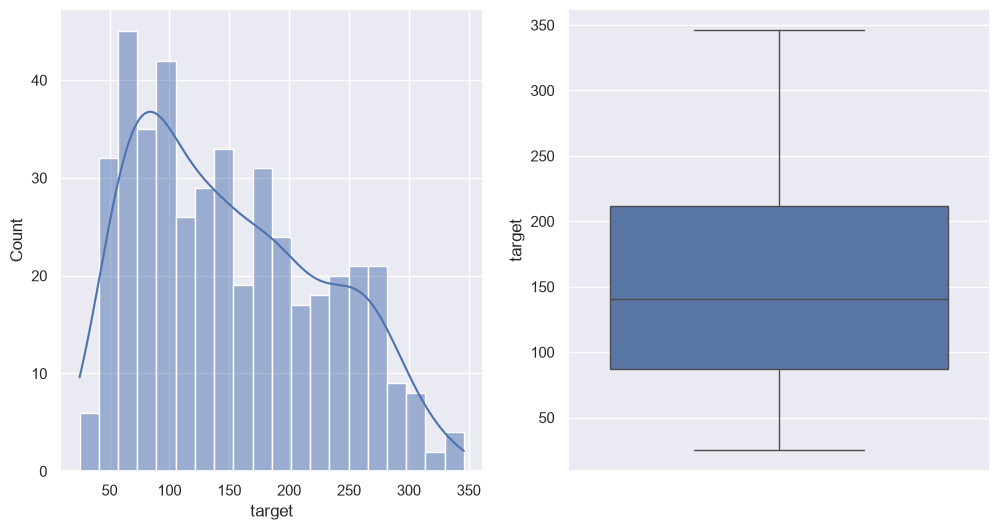

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
sns.histplot(y, bins=20, kde=True, ax=ax[0])
sns.boxplot(y, ax=ax[1]);

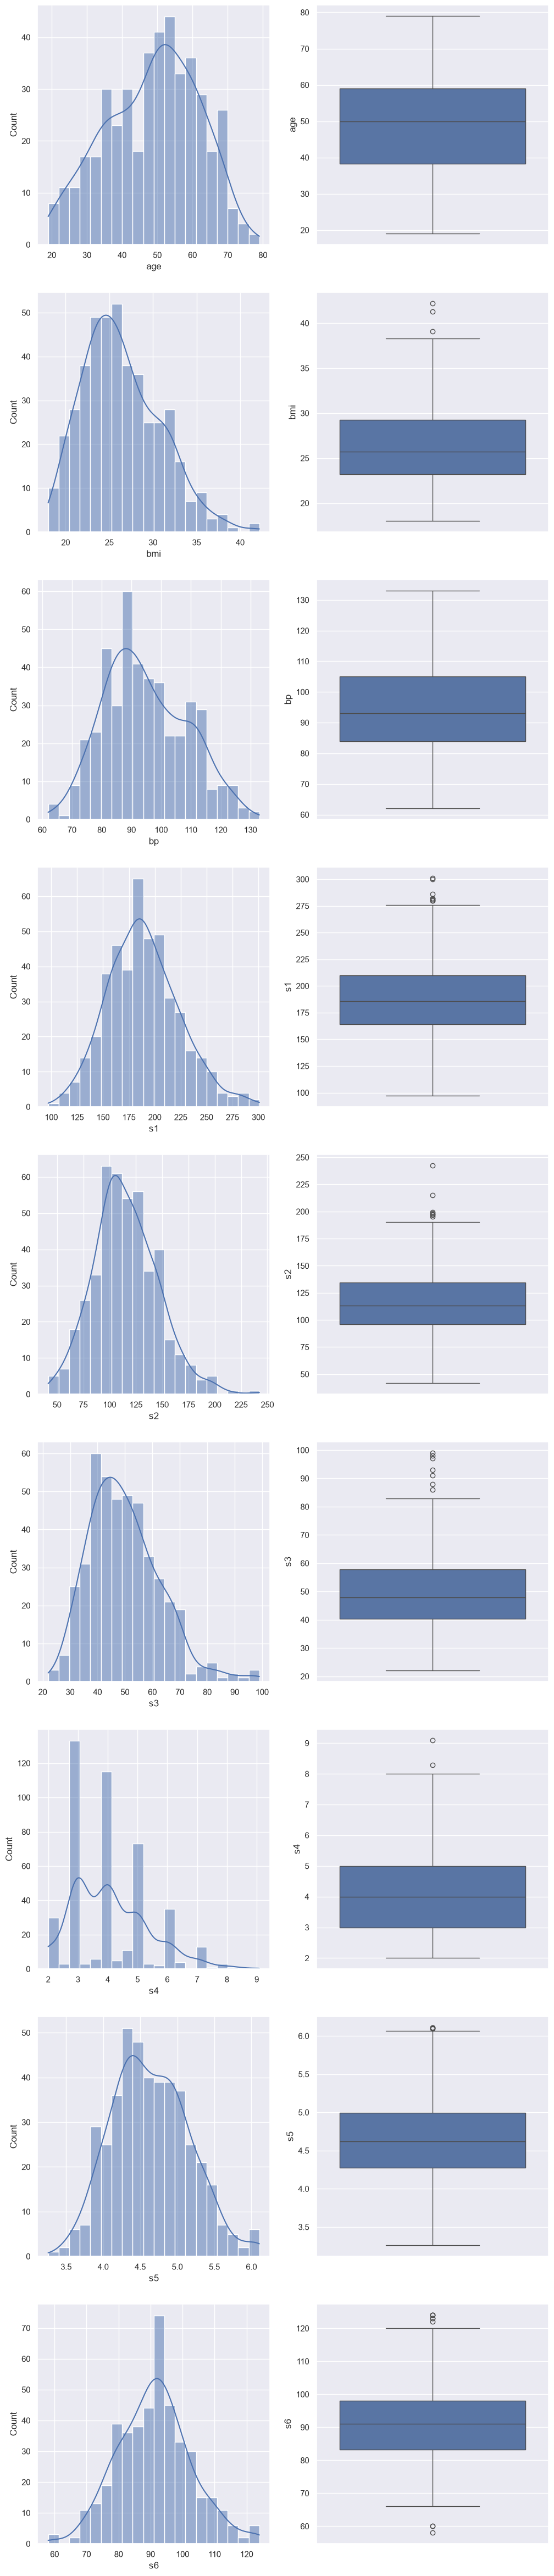

In [17]:
fig, ax = plt.subplots(len(X.columns)-1, 2, figsize=(12, 60))
for i, col in enumerate(X.drop(columns='sex').columns):
  sns.histplot(X[col], bins=20, kde=True, ax=ax[i, 0])
  sns.boxplot(X[col], ax=ax[i, 1]);

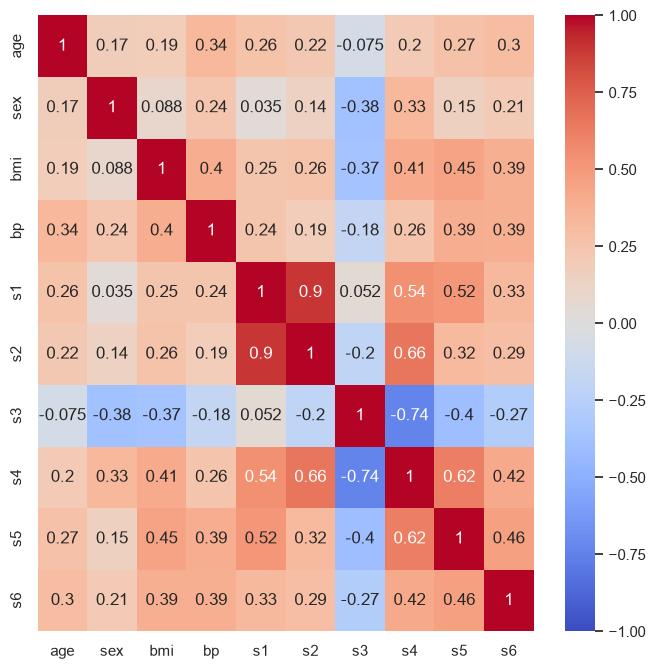

In [18]:
plt.figure(figsize=(8, 8))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm', vmin=-1);

In [19]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((331, 10), (111, 10), (331,), (111,))

In [ ]:
from sklearn.preprocessing import MinMaxScaler
sc = MinMaxScaler().set_output(transform='pandas')
X_sc_train = sc.fit_transform(X_train)
X_sc_test = sc.transform(X_test)
X_sc_train.describe()

In [ ]:
X_sc_test.describe()

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

lrd = LinearRegression()
lrd.fit(X_sc_train, y_train)
y_train_pred = lrd.predict(X_sc_train)
print(f'R2(train) = {lrd.score(X_sc_train, y_train)}')

In [ ]:
y_test_pred = lrd.predict(X_sc_test)
print(f'R2(test) = {r2_score(y_test, y_test_pred)}')

In [ ]:
sns.scatterplot(x=y_train, y=y_train_pred)
sns.lineplot(x=[y_train.min(), y_train.max()], y=[y_train_pred.min(), y_train_pred.max()], color='red');

In [ ]:
sns.scatterplot(x=y_test, y=y_test_pred)
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test_pred.min(), y_test_pred.max()], color='red');

In [ ]:
lrd.coef_

## Regresja wielomianowa 2 stopnia

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

pf = PolynomialFeatures(2, include_bias=False).set_output(transform='pandas')
X_p_train = pf.fit_transform(X_sc_train)
X_p_test = pf.transform(X_sc_test)
print(X_p_train.shape)

lrd2 = LinearRegression()
lrd2.fit(X_p_train, y_train)
print(f'R2(train) = {lrd2.score(X_p_train, y_train)}')
print(f'R2(test)  = {lrd2.score(X_p_test, y_test)}')

Komentarz

Z 10 cech robi sie 65. R2 na treningowych rosnie (0.52 -> 0.60), ale na testowych spada (0.48 -> 0.42) - model 2 stopnia sie przetrenowal, prosty model liniowy jest lepszy.